# 01 · Exploratory analysis: MovieLens-1M

Purpose: understand the data **before** modelling, with an eye on what affects evaluation:
sparsity, the popularity long tail, how activity is spread over time, and how many users and
items are cold at evaluation time.

All statistics come from tested functions in `recsys.data.eda` / `recsys.eval.protocol`; this
notebook only calls them and plots. Re-run on ML-25M by changing `CONFIG`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run from the repo root regardless of where Jupyter was started.
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)

from recsys.config import load_data_config
from recsys.data import eda
from recsys.data.preprocess import load_processed
from recsys.data.schema import AGE, GENDER, GENRES, IS_POSITIVE, ITEM_ID, RATING, TIMESTAMP, USER_ID
from recsys.data.split import load_split
from recsys.eval.protocol import eval_data_for_stage

CONFIG = "configs/data/ml-1m.yaml"
cfg = load_data_config(CONFIG)
tables = load_processed(cfg.processed_path)
inter, items, users = tables.interactions, tables.items, tables.users
split = load_split(cfg.split_path)

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# One series colour, recessive axes and grid.
SERIES, SURFACE, MUTED, INK2 = "#2a78d6", "#fcfcfb", "#898781", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titlelocation": "left", "font.size": 9.5,
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Overview

In [2]:
ov = eda.overview(inter, n_items_catalog=len(items))
pd.Series(ov, name="value").to_frame()

,value
interactions,1000209
users,6040
items_with_interactions,3706
items_in_catalog,3883
density,0.0447
positive_rate,0.5752
mean_rating,3.5816
first_interaction,2000-04-25 23:05:32
last_interaction,2003-02-28 17:49:50


In [3]:
ratings = inter[RATING].value_counts().sort_index().to_frame("count")
ratings["share"] = ratings["count"] / ratings["count"].sum()
ratings["is_positive (>= 4)"] = ratings.index >= cfg.positive_threshold
ratings

,count,share,is_positive (>= 4)
rating,,,
1.0000,56174,0.0562,False
2.0000,107557,0.1075,False
3.0000,261197,0.2611,False
4.0000,348971,0.3489,True
5.0000,226310,0.2263,True


## 2. Activity per user and per item

In [4]:
user_counts = inter.groupby(USER_ID).size()
item_counts = inter.groupby(ITEM_ID).size()
pd.DataFrame({"per_user": eda.count_distribution(user_counts),
              "per_item": eda.count_distribution(item_counts)}).round(1)

,per_user,per_item
min,20.0000,1.0000
p10,27.0000,7.0000
p25,44.0000,33.0000
p50,96.0000,123.5000
p75,208.0000,350.0000
p90,400.0000,729.5000
p99,906.7000,"1,784.9000"
max,"2,314.0000","3,428.0000"
mean,165.6000,269.9000


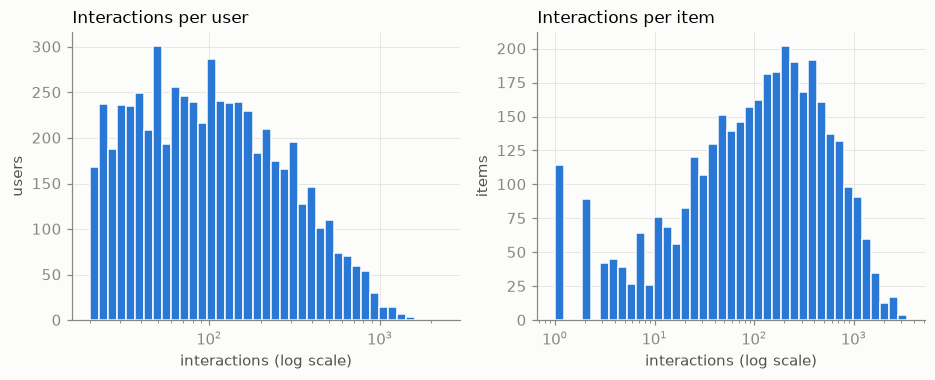

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, counts, title, unit in [
    (axes[0], user_counts, "Interactions per user", "users"),
    (axes[1], item_counts, "Interactions per item", "items"),
]:
    bins = np.logspace(np.log10(counts.min()), np.log10(counts.max()), 40)
    ax.hist(counts, bins=bins, color=SERIES, edgecolor=SURFACE, linewidth=1)
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("interactions (log scale)")
    ax.set_ylabel(unit)
fig.savefig(FIG_DIR / "activity.png")
plt.show()

## 3. Popularity long tail

In [6]:
pop = item_counts.sort_values(ascending=False).to_numpy()
shares = eda.head_share(pop, (0.01, 0.05, 0.1, 0.2, 0.5))
print(f"Gini of item popularity: {eda.gini(pop):.3f}")
print(f"Catalog movies never rated: {len(items) - len(pop)} of {len(items)}")
pd.Series({f"top {int(f * 100)}% of items": s for f, s in shares.items()},
          name="share of interactions").to_frame()

Gini of item popularity: 0.634
Catalog movies never rated: 177 of 3883


,share of interactions
top 1% of items,0.0873
top 5% of items,0.2828
top 10% of items,0.4445
top 20% of items,0.6516
top 50% of items,0.9237


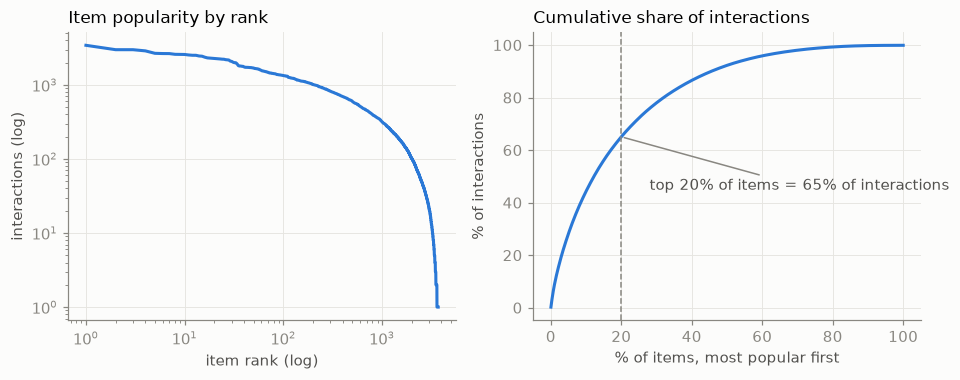

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ranks = np.arange(1, len(pop) + 1)
axes[0].loglog(ranks, pop, color=SERIES)
axes[0].set_title("Item popularity by rank")
axes[0].set_xlabel("item rank (log)")
axes[0].set_ylabel("interactions (log)")

cum = np.cumsum(pop) / pop.sum() * 100
pct_items = ranks / len(pop) * 100
axes[1].plot(pct_items, cum, color=SERIES)
axes[1].axvline(20, color=MUTED, linewidth=1, linestyle="--")
axes[1].annotate(f"top 20% of items = {shares[0.2]:.0%} of interactions",
                 xy=(20, shares[0.2] * 100), xytext=(28, 45), color=INK2,
                 arrowprops={"arrowstyle": "-", "color": MUTED})
axes[1].set_title("Cumulative share of interactions")
axes[1].set_xlabel("% of items, most popular first")
axes[1].set_ylabel("% of interactions")
fig.savefig(FIG_DIR / "long_tail.png")
plt.show()

## 4. Time: when do interactions and new users arrive?

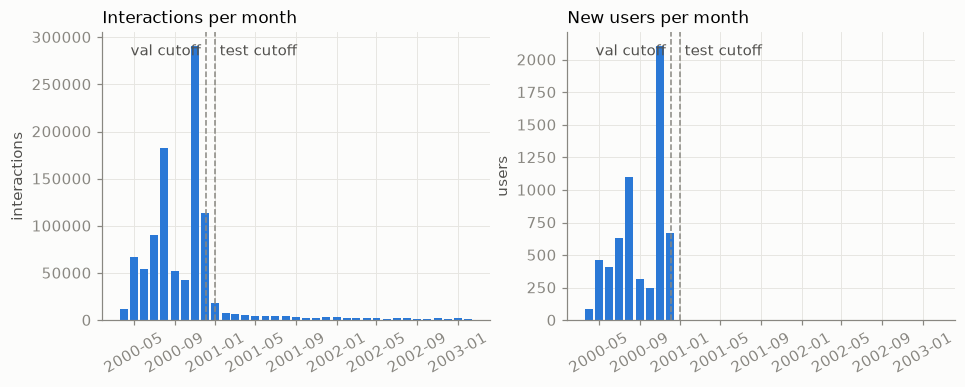

Share of interactions by year:
timestamp
2000   0.9050
2001   0.0680
2002   0.0240
2003   0.0030


In [8]:
dt = pd.to_datetime(inter[TIMESTAMP], unit="s")
monthly = dt.dt.to_period("M").value_counts().sort_index()
first_seen = pd.to_datetime(inter.groupby(USER_ID)[TIMESTAMP].min(), unit="s")
new_users = first_seen.dt.to_period("M").value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for ax, series, title, unit in [
    (axes[0], monthly, "Interactions per month", "interactions"),
    (axes[1], new_users.reindex(monthly.index, fill_value=0), "New users per month", "users"),
]:
    ax.bar(series.index.to_timestamp(), series.to_numpy(), width=24, color=SERIES)
    ax.set_title(title)
    ax.set_ylabel(unit)
    # The two cutoffs are only weeks apart: label val to the left, test to the right.
    for key, label, align in (("t_val", "val cutoff ", "right"), ("t_test", " test cutoff", "left")):
        cut = pd.to_datetime(split.meta[key], unit="s")
        ax.axvline(cut, color=MUTED, linewidth=1, linestyle="--")
        ax.text(cut, ax.get_ylim()[1] * 0.92, label, color=INK2, ha=align)
    ax.tick_params(axis="x", rotation=30)
fig.savefig(FIG_DIR / "time.png")
plt.show()

print("Share of interactions by year:")
print(dt.dt.year.value_counts(normalize=True).sort_index().round(3).to_string())

In [9]:
span = eda.user_activity_span_days(inter)
pd.Series({
    "history within 1 day": (span < 1).mean(),
    "history within 7 days": (span < 7).mean(),
    "history within 30 days": (span < 30).mean(),
    "history spans > 1 year": (span > 365).mean(),
}, name="share of users").to_frame()

,share of users
history within 1 day,0.6293
history within 7 days,0.7025
history within 30 days,0.7619
history spans > 1 year,0.1137


## 5. Cold start at evaluation time

Validation is scored with *train* as history; test with *train + val* as history (see
`recsys.eval.protocol`). A user is **cold** if they have no history at that point.

In [10]:
rows = {}
for stage in ("val", "test"):
    d = eval_data_for_stage(split, stage, n_items=len(items))
    n_rel = np.array([len(r) for r in d.relevant])
    hist_pop = d.item_popularity
    target_items = np.concatenate(d.relevant)
    rows[stage] = {
        "evaluated users (>= 1 positive)": d.n_users,
        "warm users": int(d.is_warm.sum()),
        "cold users": int((~d.is_warm).sum()),
        "median positives per user": float(np.median(n_rel)),
        "users with >= 10 positives": float((n_rel >= 10).mean()),
        "target positives on items with 0 history": float((hist_pop[target_items] == 0).mean()),
        "target positives on items with < 10 history": float((hist_pop[target_items] < 10).mean()),
    }
pd.DataFrame(rows)

,val,test
evaluated users (>= 1 positive),"1,103.0000","1,188.0000"
warm users,492.0000,"1,159.0000"
cold users,611.0000,29.0000
median positives per user,26.0000,24.0000
users with >= 10 positives,0.7335,0.7037
target positives on items with 0 history,0.0001,0.0008
target positives on items with < 10 history,0.0022,0.0050


## 6. Content: genres and demographics

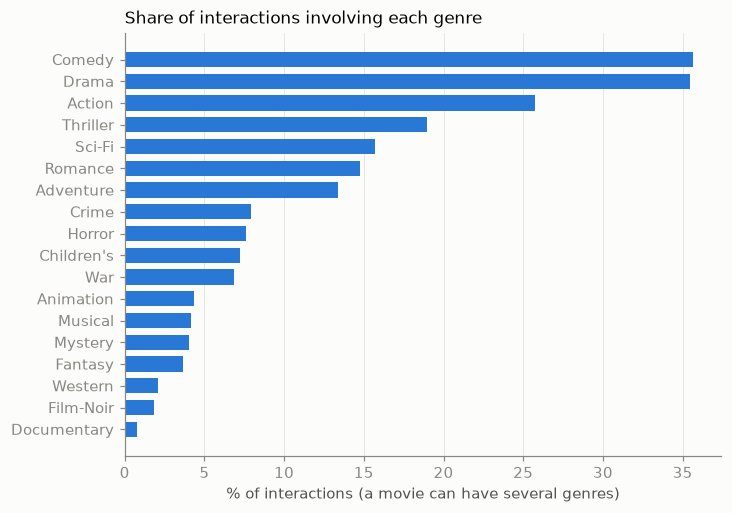

,interactions,positive_rate
genres,,
Film-Noir,18261,0.7635
Documentary,7910,0.7226
War,68527,0.6938
Drama,354529,0.6443
Crime,79541,0.6204
Animation,43293,0.6152
Mystery,40178,0.6048
Musical,41533,0.6046
Western,20683,0.5952


In [11]:
by_genre = (inter[[ITEM_ID, IS_POSITIVE]]
            .merge(items[[ITEM_ID, GENRES]], on=ITEM_ID)
            .explode(GENRES)
            .groupby(GENRES)[IS_POSITIVE].agg(interactions="size", positive_rate="mean")
            .sort_values("interactions"))
by_genre["share"] = by_genre["interactions"] / len(inter)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(by_genre.index, by_genre["share"] * 100, color=SERIES, height=0.7)
ax.set_title("Share of interactions involving each genre")
ax.set_xlabel("% of interactions (a movie can have several genres)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "genres.png")
plt.show()
by_genre.sort_values("positive_rate", ascending=False)[["interactions", "positive_rate"]]

In [12]:
demo = users[[USER_ID, GENDER, AGE]].merge(user_counts.rename("n").reset_index(), on=USER_ID)
display(demo.groupby(GENDER)["n"].agg(users="size", median_interactions="median"))
display(demo.groupby(AGE)["n"].agg(users="size", median_interactions="median"))

,users,median_interactions
gender,,
F,1709,77.0000
M,4331,102.0000


,users,median_interactions
age,,
1,222,77.0000
18,1103,100.0000
25,2096,110.0000
35,1193,94.0000
45,550,81.0000
50,496,88.0000
56,380,64.0000


## 7. Takeaways (ML-1M, numbers from the cells above)

| Finding | Number | Consequence for the project |
|---|---|---|
| Sparse matrix | density 4.47%, 57.5% of ratings are positives (>= 4) | Implicit-feedback models; most user-item pairs are unobserved, not negative |
| Strong long tail | top 20% of items = 65% of interactions, Gini 0.634 | Most-popular will be a hard baseline; track coverage and popularity bias; motivates logQ correction in the two-tower model |
| Activity in bursts | 90.5% of interactions in 2000; 62.9% of users rated everything within one day | Short-term sequence features matter; a global time split leaves val/test small and uneven |
| No new users after Dec 2000 | new-user chart drops to zero | Val (4 weeks) is 55% cold users; test (26 months) is 97.6% warm returning users |
| Many positives per test user | median 24 (test) | Recall@10 ceiling is ~0.53 (oracle). Compare models relatively; report NDCG too |
| Cold items are negligible | 0.08% of test positives are on items with no history | ID-only item embeddings are fine on ML-1M; content features matter more for users |
| Genre affects taste | Film-Noir 76% positive vs Horror 45% | Genre-affinity cross features for the ranker (Phase 4) |

**Protocol decision:** because val is cold-heavy and test is almost entirely warm, model selection
uses the **warm-user segment of val** (NDCG@10), and all/warm/cold are always reported separately.